In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.patches import Rectangle     # for creating custom legend handles
from tabulate import tabulate                # for displaying tables in a readable format (on categorical features)

# ✅ 1. Data Quality Assessment 

In [2]:
df = pd.read_csv("heart_disease.csv")
Data = pd.DataFrame(df)
display(Data.head(10))

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
5,57,1,0,140,192,0,1,148,0,0.4,1,0,1,1
6,56,0,1,140,294,0,0,153,0,1.3,1,0,2,1
7,44,1,1,120,263,0,1,173,0,0.0,2,0,3,1
8,52,1,2,172,199,1,1,162,0,0.5,2,0,3,1
9,57,1,2,150,168,0,1,174,0,1.6,2,0,2,1


In [3]:
print(f"\nThe shape of Dataframe is : \n\n{Data.shape}")


The shape of Dataframe is : 

(303, 14)


In [4]:
total_cells = Data.shape[0] * Data.shape[1]     # counting total number of cells in the DataFrame 
                                                # counting total number of rows and columns in the DataFrame
print(f"\nthe total number of data in Data is : {total_cells}")


the total number of data in Data is : 4242


In [5]:
print(f"\nThe feture' names of Dataframe are : \n\n{Data.columns}")


The feture' names of Dataframe are : 

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')


In [6]:
Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [7]:
print("\nDescriptive statistics of the Dataframe are : \n")
Data.describe(include="all")


Descriptive statistics of the Dataframe are : 



,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


> ##### Age = Mean: 54.4 years / Median: 55 years / Std: 9.08 -> So the population is mainly in the middle-aged to elderly range and the age distribution is medium. Fairly balanced distribution, reasonable range.
> ##### Trestbps = Mean : 131.6 / Median : 130 / Min : 94 / Max : 200 -> The mean and median are close, but Max=200 indicates high values ​​/ possible outliers.Probability of extreme values ​​on the high side
> ##### Chol =  Mean : 246.3 / Median : 240 / Q3 : 274.5 / Max : 564 -> 564 is very high compared to Q3=274.5, so this could be a sign of right-skewness and the presence of extreme values. Serious suspect of skew/outlier
> ##### Thalach = Mean : 149.65 / Median : 153 / Min : 71 / Max : 202 -> The mean and median are relatively close, but the range is very large. The value 71 in particular could be an unusual observation.
> ##### Oldpeak = Mean : 1.04 / Median : 0.8 / Max : 6.2 -> Median is less than Mean ( 0.8 < 1.04 ), So this can usually be a sign of a right-skewed distribution.
> ##### Variables like : cp / restecg / slope /ca / thal -> are numbers, but they are not necessarily continuous numerical features.

In [8]:
print(f"\nThe number of unique values for each Feature : \n\n{Data.nunique()}")


The number of unique values for each Feature : 

age          41
sex           2
cp            4
trestbps     49
chol        152
fbs           2
restecg       3
thalach      91
exang         2
oldpeak      40
slope         3
ca            5
thal          4
target        2
dtype: int64


> ##### ["age", "trestbps", "chol", "thalach", "oldpeak"] are Numerical / continuous.
> ##### ["sex", "cp", "fbs", "restecg", "exang","slope", "ca", "thal"] are Categorical.
> ##### ["target"] is Binary

In [9]:
print(f"\nThe number of duplicate values are : {Data.duplicated().sum()}")


The number of duplicate values are : 1


> ##### It is better to remove it because it does not add new information and can affect descriptive statistics and analyses.

In [10]:
Data[Data.duplicated()]              # Let"s look at duplicate first.
Data[Data.duplicated(keep=False)]    # Which previous row is a duplicate?

Data = Data.drop_duplicates()

print(f"\nThe number of duplicate values are : {Data.duplicated().sum()}")


The number of duplicate values are : 0


In [11]:
# Total number of missing values in the DataFrame

total_missing = Data.isnull().sum().sum()
total_cells = Data.shape[0] * Data.shape[1]

missing_percent = (total_missing / total_cells) * 100

print(f"\nTotal number of missing values in the DataFrame are :")
print(f"\nTotal Missing Values -> {total_missing}")
print(f"\nMissing Percentage -> {missing_percent:.2f}%")


Total number of missing values in the DataFrame are :

Total Missing Values -> 0

Missing Percentage -> 0.00%


# ✅ 2. Features Understanding 

## 2.1. The numerical features

In [12]:
numerical_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]

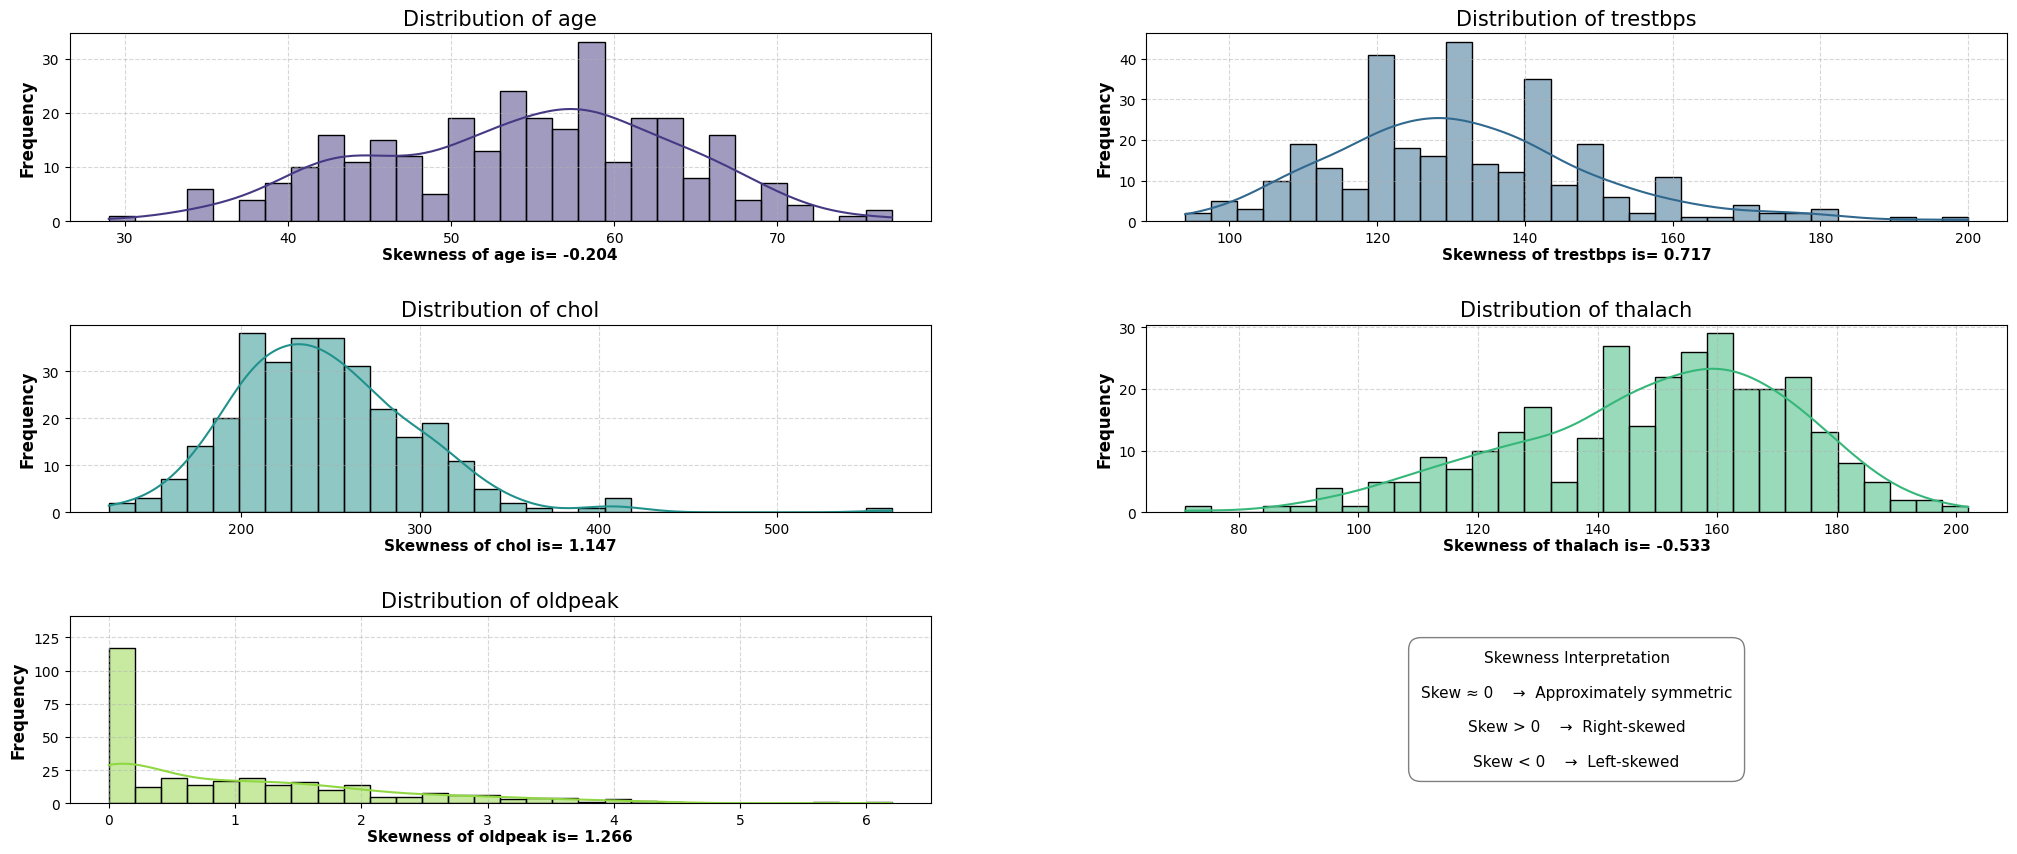

In [13]:
fig, axes = plt.subplots(3, 2, figsize=(25, 10))
axes = axes.flatten()

plt.subplots_adjust(
    wspace=0.25,   
    hspace=0.55    
)

palette = sns.color_palette("viridis", n_colors=len(numerical_cols))

for i, col in enumerate(numerical_cols):

    sns.histplot(
        Data[col],
        bins=30,
        kde=True,
        color=palette[i],
        ax=axes[i]
    )

    skewness = Data[col].skew()
    axes[i].set_title(
        f"Distribution of {col}",
        fontsize=15
    )
    axes[i].set_xlabel("")
    axes[i].set_ylabel(
        "Frequency",
        fontsize=12,
        fontweight="bold"
    )

    # Grid
    axes[i].grid(
        True,
        linestyle="--",
        alpha=0.5
    )

    # Skewness
    axes[i].text(
        0.5, -0.20,
        f"Skewness of {col} is= {skewness:.3f}",
        transform=axes[i].transAxes,
        ha="center",
        fontsize=11,
        fontweight="bold"
    )


# Personalized legend
axes[-1].axis("off")

axes[-1].text(
    0.5, 0.5,
    
    "Skewness Interpretation\n\n"
    "Skew ≈ 0    →  Approximately symmetric\n\n"
    "Skew > 0    →  Right-skewed\n\n"
    "Skew < 0    →  Left-skewed",

    transform=axes[-1].transAxes,
    ha="center",
    va="center",
    fontsize=11,

    bbox=dict(
        boxstyle="round,pad=0.8",
        facecolor="white",
        edgecolor="gray"
    )
)

ymin, ymax = axes[i].get_ylim()          # Get the current y-axis limits for each subplot, so we can adjust some space above the bars for the labels to fit in
axes[i].set_ylim(ymin, ymax * 1.15)

plt.show()

> ##### Age is almost symmetric.This means that the age distribution is not very far from symmetrical.
> ##### thalach has negative skewness. This means that the tails of the distribution are pulled more towards lower values.
> ##### trestbps is close to 1. This means that a few relatively high values ​​have caused the right tail of the distribution to be longer.
> ##### In Chol the situation is clearer. The positive skewness is high; that is, the distribution of Chol is skewed towards high values. This feature is definitely worth checking for Outlier.
> ##### In oldpeak, the distribution is skewed towards high values ​​and we probably have a few observations with high oldpeak. This is also one of the features that should be carefully examined in the next step.

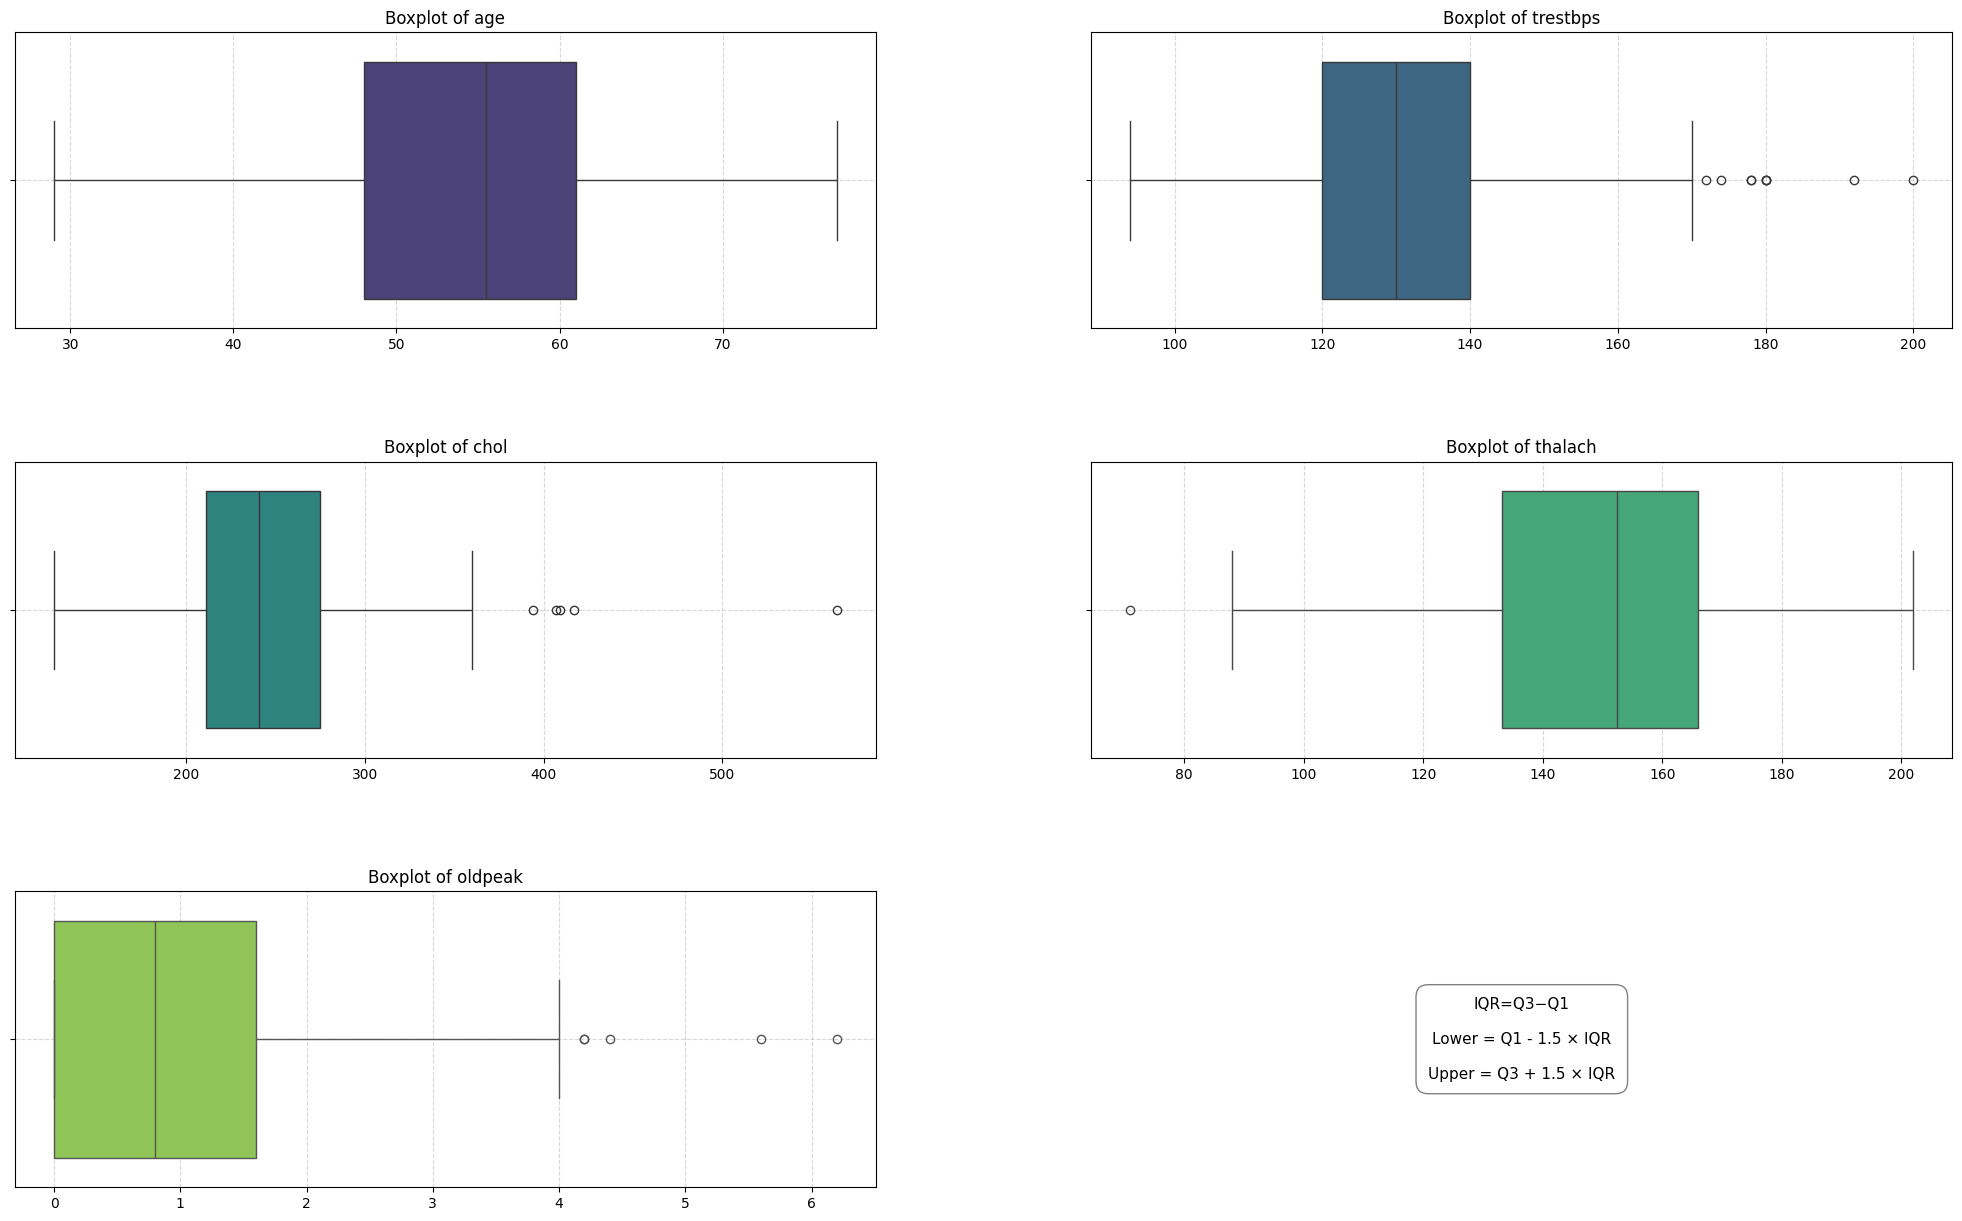

In [14]:
fig, axes = plt.subplots(3, 2, figsize=(25, 15))
axes = axes.flatten()

plt.subplots_adjust(
    wspace=0.25,
    hspace=0.45
)

palette = sns.color_palette("viridis", n_colors=len(numerical_cols))

for i, col in enumerate(numerical_cols):

    sns.boxplot(
        x=Data[col],
        color=palette[i],
        ax=axes[i]
    )

    axes[i].set_title(f"Boxplot of {col}")
    axes[i].set_xlabel("")

    axes[i].grid(
        True,
        linestyle="--",
        alpha=0.5
    )

# Personalized legend
axes[-1].axis("off")

axes[-1].text(
    0.5, 0.5,
    
    "IQR=Q3−Q1\n\n"
    "Lower = Q1 - 1.5 × IQR\n\n"
    "Upper = Q3 + 1.5 × IQR",

    transform=axes[-1].transAxes,
    ha="center",
    va="center",
    fontsize=11,

    bbox=dict(
        boxstyle="round,pad=0.8",
        facecolor="white",
        edgecolor="gray"
    )
)

plt.show()

In [15]:
outlier_summary = []

for col in numerical_cols:

    Q1 = Data[col].quantile(0.25)
    Q3 = Data[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = Data[
        (Data[col] < lower_bound) |
        (Data[col] > upper_bound)
    ]

    outlier_summary.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier %": len(outliers) / len(Data) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,age,48.00,61.00,13.00,28.500,80.500,0,0.000000
1,trestbps,120.00,140.00,20.00,90.000,170.000,9,2.980132
2,chol,211.00,274.75,63.75,115.375,370.375,5,1.655629
3,thalach,133.25,166.00,32.75,84.125,215.125,1,0.331126
4,oldpeak,0.00,1.60,1.60,-2.400,4.000,5,1.655629


> ##### trestbps : 9 people have trestbps > 170. These are statistically outliers, but we should not dismiss them. Because high resting blood pressure can be quite real from a medical perspective.
> ##### chol : 5 have values ​​above about 370. This is quite consistent with what we saw in the Distribution, which is that chol was both right-skewed and had a few extreme values.
> ##### oldpeak : We have 5 values ​​higher than 4. This is also perfectly consistent with the previous Skewness, so oldpeak has a right-skewed distribution + a few extreme values.
> ##### The other two features, age, which has completely logical conditions and does not need to be checked, and thalach also has only 1 outlier. Given that Min = 71, the outlier data is probably this value of 71.

> ##### Pay attention to the table below:
> | Feature  | Skewness | Outliers |
> |----------|---------:|---------:|
> | age      |   -0.204 |        0 |
> | thalach  |   -0.533 |        1 |
> | trestbps |    0.717 |        9 |
> | chol     |    1.147 |        5 |
> | oldpeak  |    1.266 |        5 |
> ##### It shows: chol and oldpeak both have the highest positive skewness and high outliers.

## 2.2. The Categorical features

In [16]:
categorical_cols = ["sex", "cp", "fbs", "restecg","exang", "slope", "ca", "thal"]

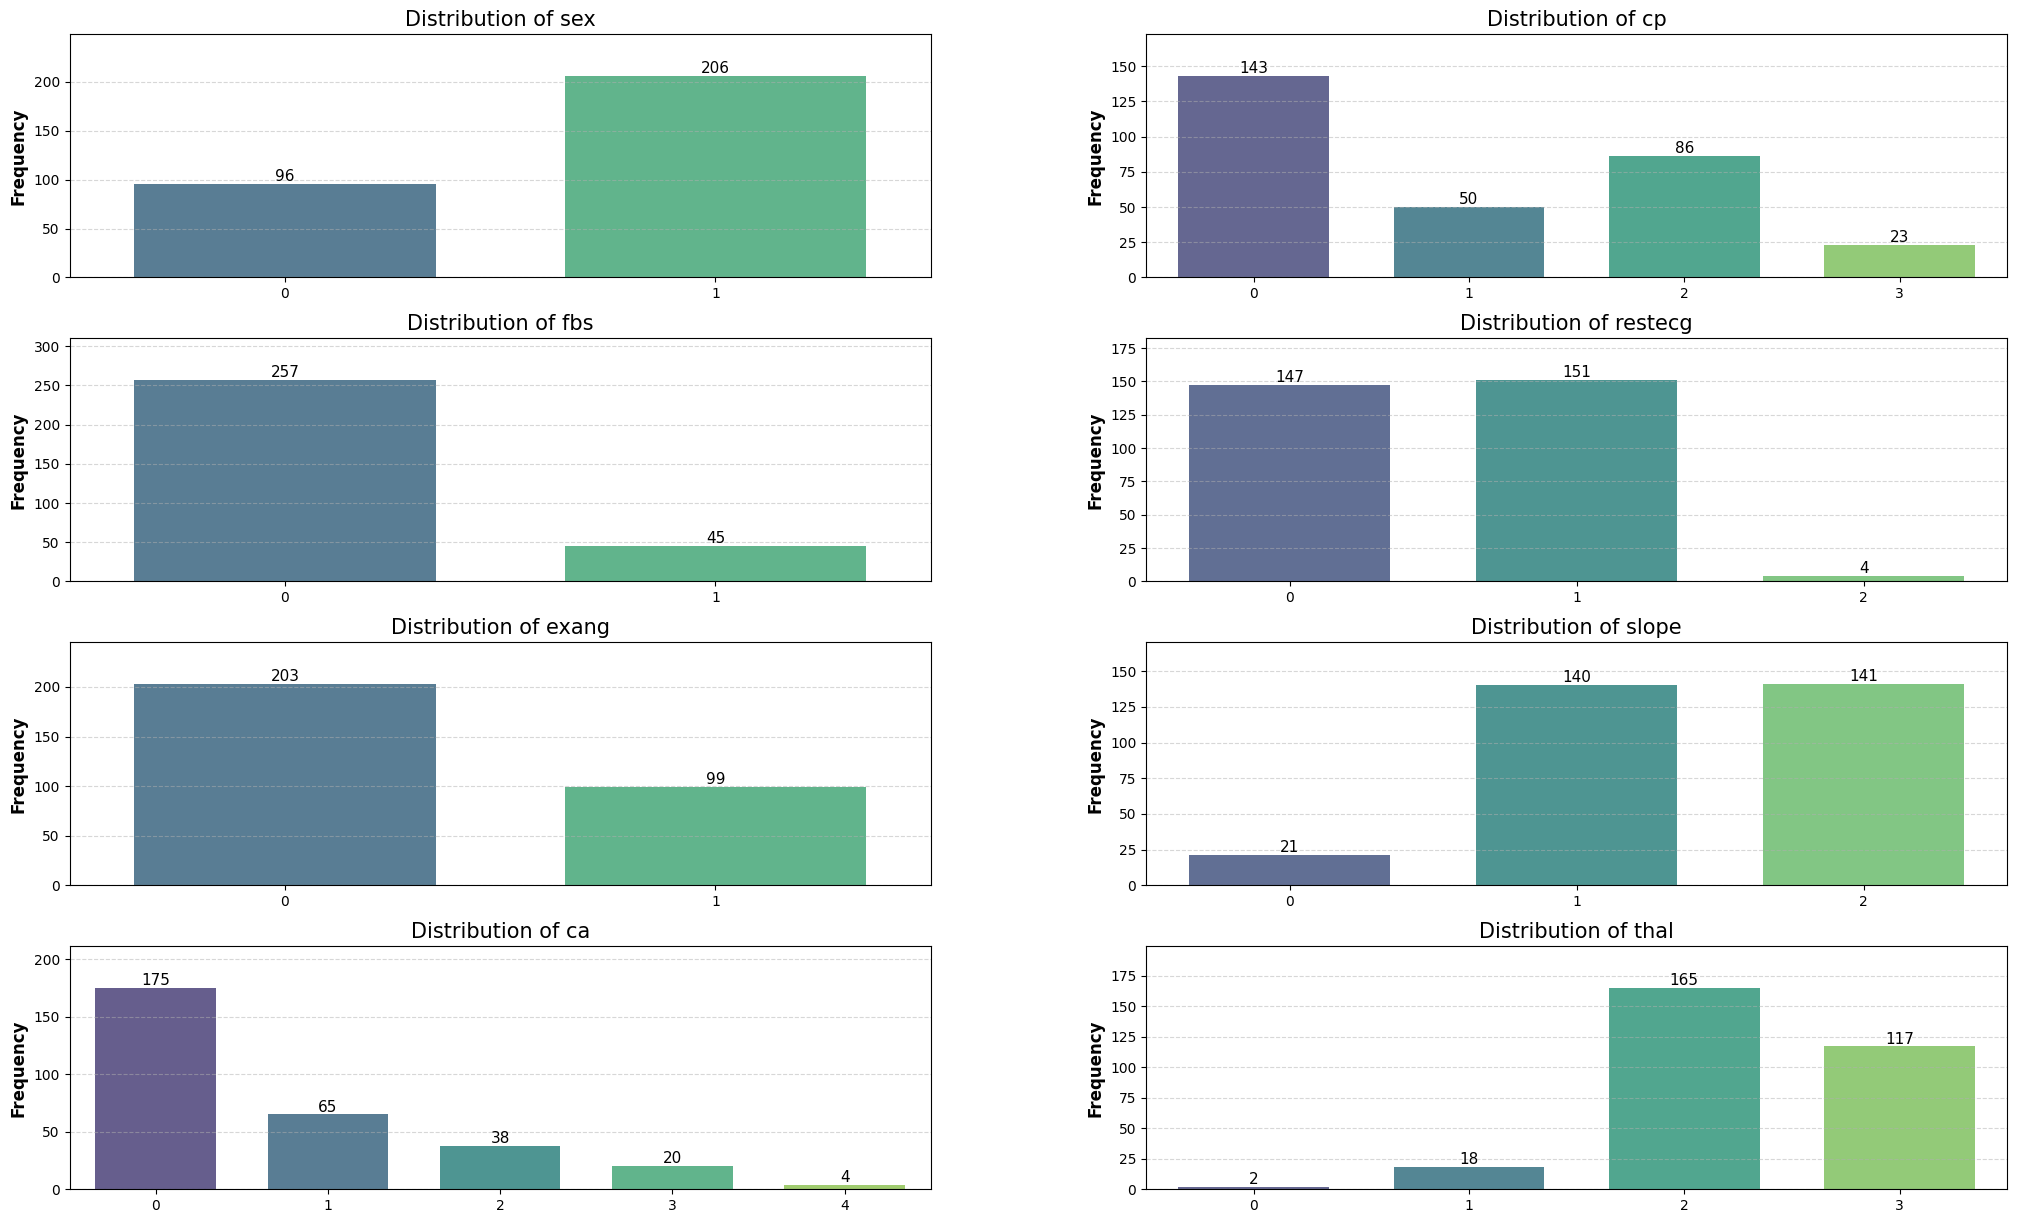

In [17]:
fig, axes = plt.subplots(4, 2, figsize=(25, 15))
axes = axes.flatten()

plt.subplots_adjust(
    wspace=0.25,
    hspace=0.25
)

for i, col in enumerate(categorical_cols):

    n_categories = Data[col].nunique()
    palette = sns.color_palette("viridis", n_colors=n_categories)

    sns.countplot(
        data=Data,
        x=col,
        hue=col,
        width=0.7,
        alpha=0.85,
        palette=palette,
        legend=False,
        ax=axes[i]
    )

    axes[i].set_title(
        f"Distribution of {col}",
        fontsize=15
    )
    axes[i].set_xlabel("")
    axes[i].set_ylabel(
        "Frequency",
        fontweight="bold",
        fontsize=12
    )

    axes[i].grid(
        True,
        axis="y",
        linestyle="--",
        alpha=0.5
    )

    for container in axes[i].containers:
        axes[i].bar_label(container, fontsize=11)

    ymin, ymax = axes[i].get_ylim()          # Get the current y-axis limits for each subplot, so we can adjust some space above the bars for the labels to fit in
    axes[i].set_ylim(ymin, ymax * 1.15)

plt.show()

> ##### Plot analysis
>> ##### Sex is relatively unbalanced, with class 1 being dominant.
>> ##### cp is unbalanced and has a small number of cp=3. Needs further investigation.
>> ##### fbs is severely unbalanced, with about 85% of the data in class 0.
>> ##### restecg = 2 is very rare. Only 4 samples have a value of 2. Needs further investigation.
>> ##### exang is relatively unbalanced.
>> ##### slope=0 is low and values ​​of 1 and 2 are almost equal.
>> ##### ca is highly unbalanced and ca=4 is very rare. Only 4 samples have a value of 4. Needs further investigation.
>> ##### thal is highly unbalanced and the values ​​0 and 1 are few. Only 2 samples have a value of 0 and 18 samples have a value of 1.Needs further investigation.

## 2.3. Target Distribution

In [18]:
target_counts = Data["target"].value_counts().sort_index()
target_percent = Data["target"].value_counts(normalize=True).sort_index() * 100

summary_df = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_percent.round(2)
})
summary_df.index.name = "Target"

summary_df

,Count,Percentage (%)
Target,,
0,138,45.7
1,164,54.3


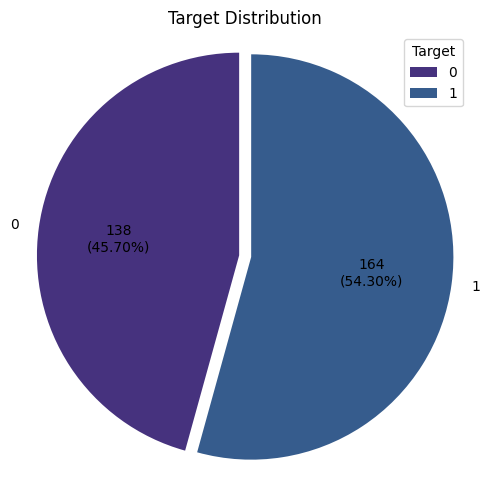

In [19]:
plt.figure(figsize=(5, 5))

target_counts = Data["target"].value_counts().sort_index()
total = len(Data)
colors = sns.color_palette("viridis")

wedges, texts, autotexts = plt.pie(
    target_counts,
    labels=target_counts.index,
    autopct=lambda pct: f"{int(round(pct / 100 * total))}\n({pct:.2f}%)",
    startangle=90,
    colors=colors,
    explode=[0.03] * len(target_counts)
)

plt.title("Target Distribution")
plt.axis("equal")

plt.legend(
    wedges,
    target_counts.index,
    title="Target",
    loc="upper right",
    bbox_to_anchor=(1, 1)
)


plt.tight_layout()
plt.show()

> ##### Target is fairly balanced and does not have a severe class imbalance.

# ✅ 3. Distribution between features and target

## 3.1. Numerical Features

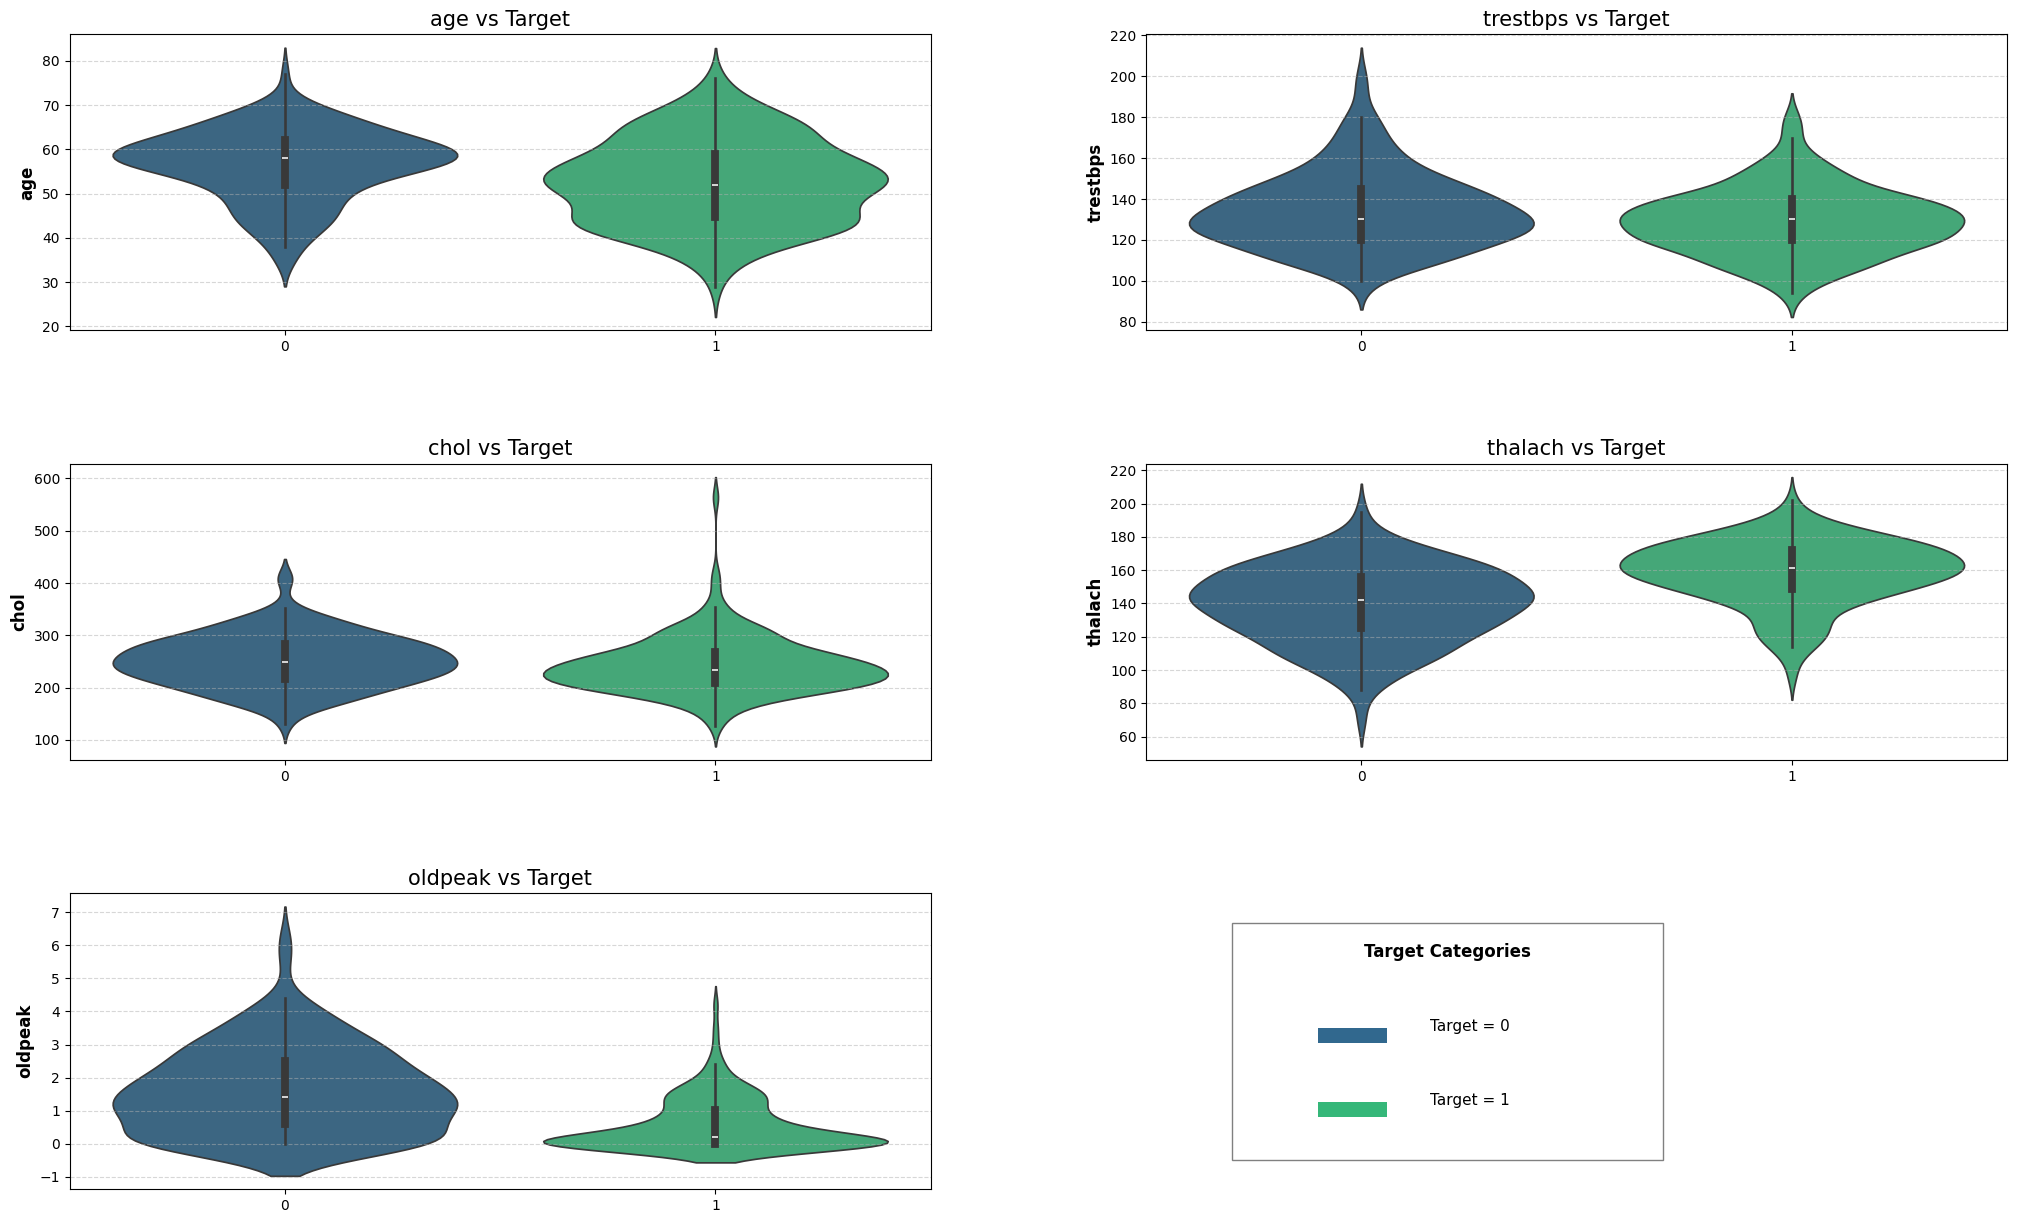

In [20]:
fig, axes = plt.subplots(3, 2, figsize=(25, 15))
axes = axes.flatten()

plt.subplots_adjust(
    wspace=0.25,
    hspace=0.45
)

n_categories = Data["target"].nunique()
palette = sns.color_palette("viridis", n_colors=n_categories)
categories = sorted(Data["target"].unique())

for i, col in enumerate(numerical_cols):

    sns.violinplot(
        data=Data,
        x="target",
        y=col,
        hue="target",
        palette=palette,
        legend=False,
        inner="box",
        ax=axes[i]
    )

    axes[i].set_title(
        f"{col} vs Target",
        fontsize=15
    )
    axes[i].set_xlabel("")
    axes[i].set_ylabel(
        col,
        fontweight="bold",
        fontsize=12
    )

    axes[i].grid(
        True,
        axis="y",
        linestyle="--",
        alpha=0.5
    )

axes[-1].axis("off")     # Deleting the sixth subplot

# Personalized legend
axes[-1].add_patch(
    Rectangle(
        (0.1, 0.1), 0.5, 0.8,
        transform=axes[-1].transAxes,
        facecolor="white",
        edgecolor="gray",
        linewidth=1
    )
)

axes[-1].text(
    0.35, 0.8,
    "Target Categories",
    transform=axes[-1].transAxes,
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold"
)

y_start = 0.55
for i, cat in enumerate(categories):
    y = y_start - i * 0.25

    axes[-1].add_patch(
        Rectangle(
            (0.2, y - 0.055), 0.08, 0.05,
            transform=axes[-1].transAxes,
            facecolor=palette[i],
            edgecolor="none"
        )
    )

    axes[-1].text(
        0.33, y,
        f"Target = {cat}",
        transform=axes[-1].transAxes,
        ha="left",
        va="center",
        fontsize=11
    )

plt.show()

> |Feature |          Conditions           | Description |
> |--------|-------------------------------|-------------|
> |age     |The difference is visible | target=0 is skewed towards older ages, while target=1 has a lower distribution center. Overlap is still significant| 
> |trestbps|The difference is weak | Both classes are almost overlapping. There is not much differenc|
> |chol    |Relatively weak difference | Both classes have a lot of overlap. target=1 has a higher tail and extreme outliers are also seen, but the centers of the two distributions are not too far apart|
> |thalach |The difference is very clear | The two groups overlap, but their locations are clearly different |
> |oldpeak |This is the most obvious difference | The shape of the distributions for the two groups is also very different. For target=1, a large portion of the observations are concentrated near 0, but for target=0, the distribution is skewed towards higher values|

In [21]:
Data.groupby("target")[numerical_cols].agg(
    ["mean", "median", "std"]
).round(2)

age              trestbps                  chol                \
         mean median   std     mean median    std    mean median    std   
target                                                                    
0       56.60   58.0  7.96   134.40  130.0  18.73  251.09  249.0  49.45   
1       52.59   52.0  9.51   129.25  130.0  16.20  242.64  234.5  53.46   

       thalach              oldpeak               
          mean median   std    mean median   std  
target                                            
0       139.10  142.0  22.6    1.59    1.4  1.30  
1       158.38  161.0  19.2    0.59    0.2  0.78

> |Feature |          Conditions           |                       Description                      |                    Result                     |
> |--------|-------------------------------|--------------------------------------------------------|-----------------------------------------------|
> |age     |difference is significant      | Difference between target 0, 1 in both median and mean | age is definitely worth further investigation |
> |trestbps|difference is relatively small | We have a difference of about 5 units in the mean, but the median is exactly the same.|We cannot say that the difference in distribution is very strong |
> |chol    |difference is moderate         | Mean is slightly different but median is more different| It should be further investigated |
> |thalach |difference is clear            | The target=1 group has a much higher maximum heart rate, both in mean and median | It should be further investigated |
> |oldpeak |difference is very clear       | The most obvious difference is between mean and median | It should be further investigated |
> ##### Among these variables, thalach and oldpeak show particularly clear differences between the two target groups.

## 3.2. Categorical Features

In [22]:
for col in categorical_cols:

    # Counts
    counts = pd.crosstab(
        Data[col],
        Data["target"]
    )

    # Percentages within each category
    percentages = pd.crosstab(
        Data[col],
        Data["target"],
        normalize="index"
    ) * 100

    # Count + Percentage
    summary = pd.DataFrame(index=counts.index)

    for target in counts.columns:
        summary[f"Target {target}"] = (
            counts[target].astype(str)
            + " ("
            + percentages[target].round(1).astype(str)
            + "%)"
        )

    summary.index.name = col

    print(f"\n{"=" * 50}")
    print(f"{col} vs Target")
    print(f"{"=" * 50}")
    display(summary)


sex vs Target


,Target 0,Target 1
sex,,
0,24 (25.0%),72 (75.0%)
1,114 (55.3%),92 (44.7%)



cp vs Target


,Target 0,Target 1
cp,,
0,104 (72.7%),39 (27.3%)
1,9 (18.0%),41 (82.0%)
2,18 (20.9%),68 (79.1%)
3,7 (30.4%),16 (69.6%)



fbs vs Target


...

,Target 0,Target 1
slope,,
0,12 (57.1%),9 (42.9%)
1,91 (65.0%),49 (35.0%)
2,35 (24.8%),106 (75.2%)



ca vs Target


,Target 0,Target 1
ca,,
0,45 (25.7%),130 (74.3%)
1,44 (67.7%),21 (32.3%)
2,31 (81.6%),7 (18.4%)
3,17 (85.0%),3 (15.0%)
4,1 (25.0%),3 (75.0%)



thal vs Target


,Target 0,Target 1
thal,,
0,1 (50.0%),1 (50.0%)
1,12 (66.7%),6 (33.3%)
2,36 (21.8%),129 (78.2%)
3,89 (76.1%),28 (23.9%)


> |Feature |          Conditions             |                       Description                      |
> |--------|---------------------------------|--------------------------------------------------------|
> |sex     |A significant difference is seen | In sex=0, target=1 it is about 75%, but in sex=1 it is about 45% | 
> |cp      |The difference between the categories is very clear | Especially cp=0 vs cp=1/2/3 |
> |fbs     |Almost no difference         | The target ratio in the two categories is almost the same. | 
> |restecg |Not reliable.            | 0 and 1 are different, but 2 only has 4 examples |
> |exang   |Very clear difference       | exang=0 → 69.5% target=1, vs. exang=1 → 23.2% |
> |slope   |Clear difference           | Specifically slope=2 → 75.2% target=1 vs slope=1 → 35% |
> |ca      |Very clear difference      | ca=0 → 74.3% target=1, but ca=2/3 → about 18%/15% |
> |thal    |Very clear difference        | thal=2 → 78.2% target=1, thal=3 → 23.9% |

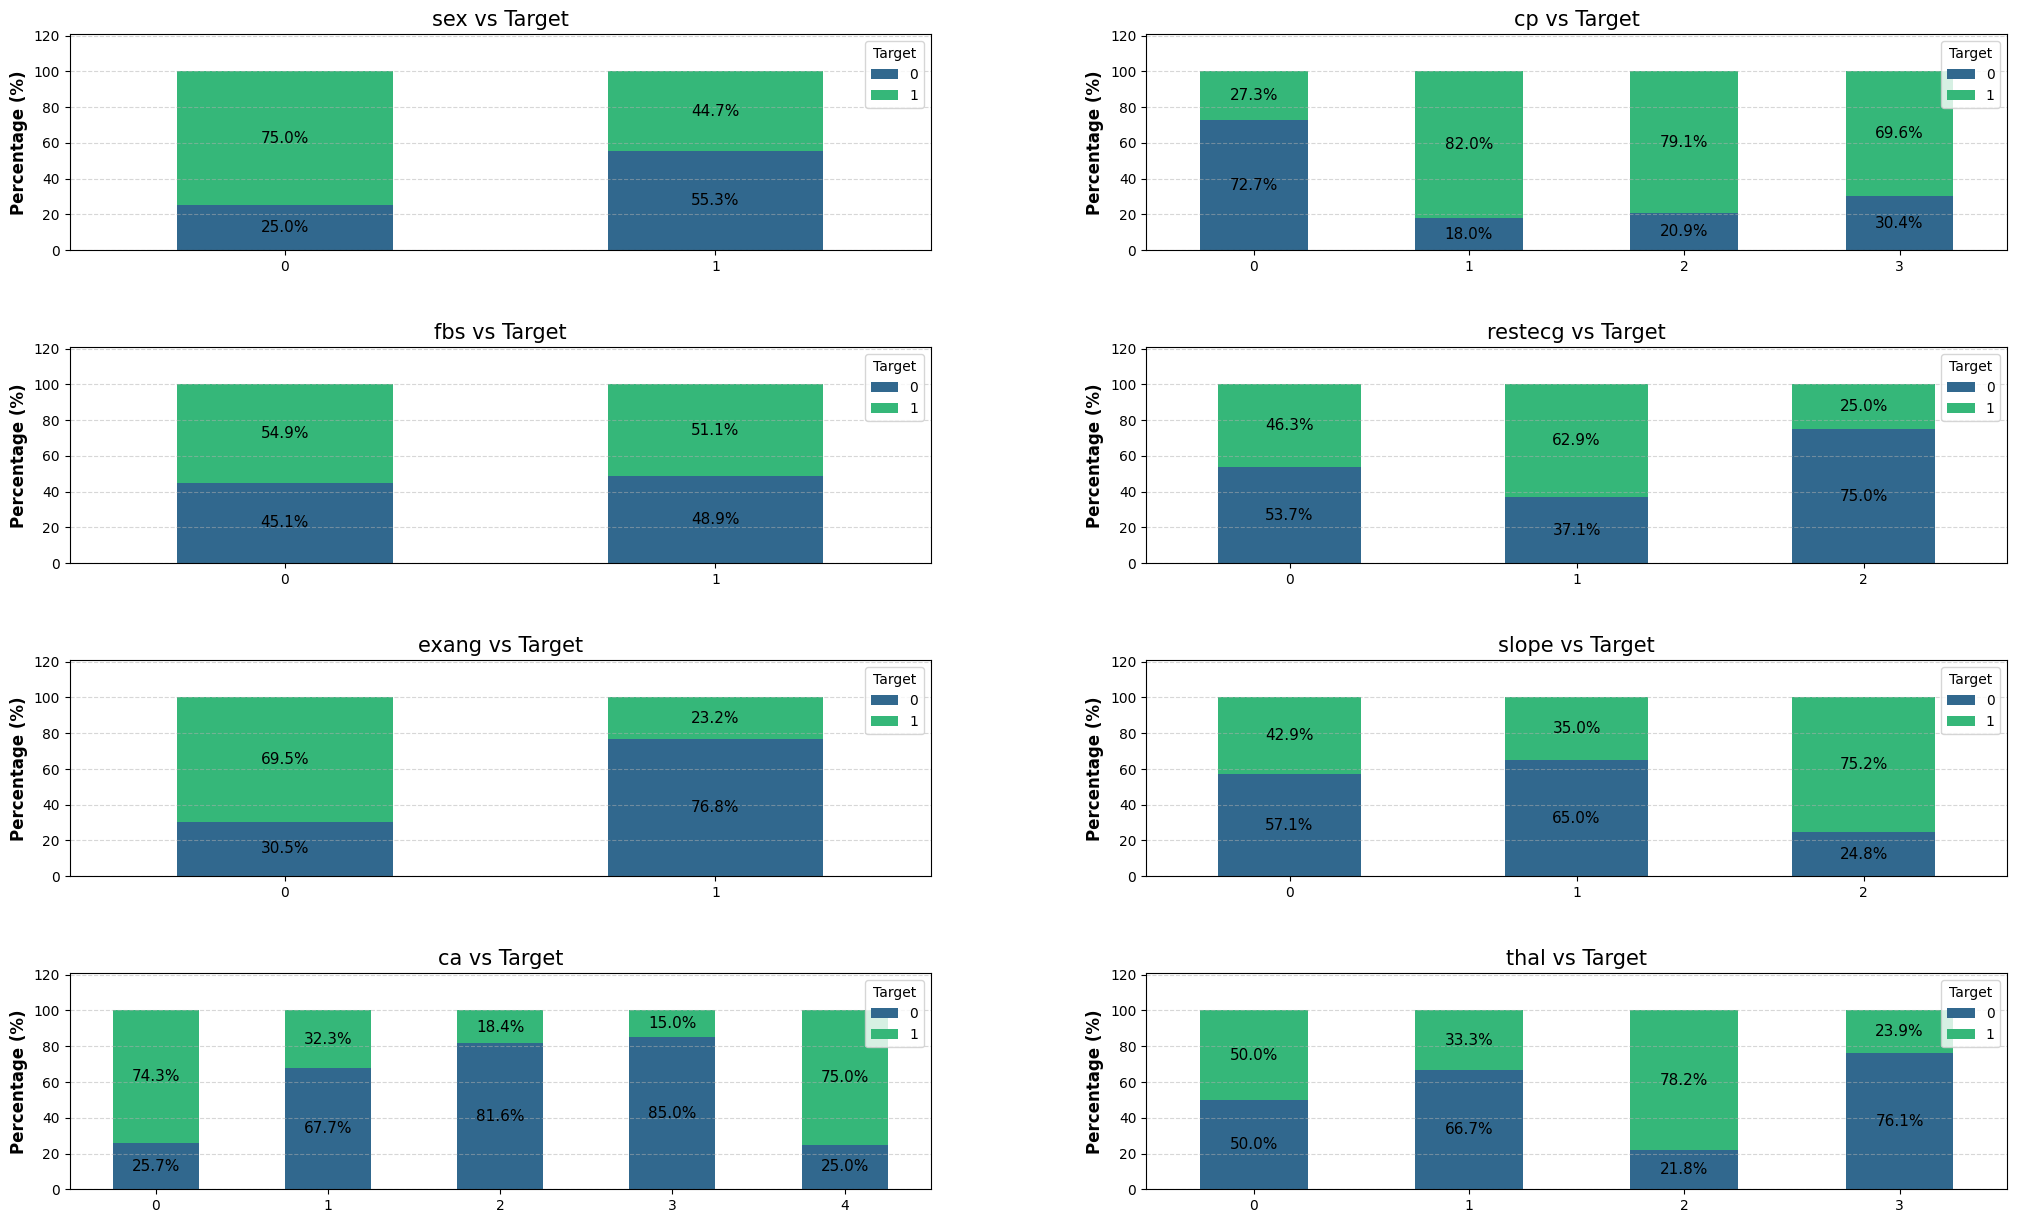

In [23]:
fig, axes = plt.subplots(4, 2, figsize=(25, 15))
axes = axes.flatten()

plt.subplots_adjust(
    wspace=0.25,
    hspace=0.45
)

n_categories = Data["target"].nunique()
palette = sns.color_palette("viridis", n_colors=n_categories)

for i, col in enumerate(categorical_cols):

    ct = pd.crosstab(
        Data[col],
        Data["target"],
        normalize="index"
    ) * 100

    ct.plot(
        kind="bar",
        stacked=True,
        color=palette,
        ax=axes[i]
    )

    for container in axes[i].containers:
        axes[i].bar_label(
            container,
            fmt="%.1f%%",
            label_type="center",
            fontsize=11,
            color="black"
    )

    axes[i].set_title(
        f"{col} vs Target",
        fontsize=15
        )
    axes[i].set_xlabel("")
    axes[i].set_ylabel(
        "Percentage (%)",
        fontweight="bold",
        fontsize=12
        )

    axes[i].grid(
        True,
        axis="y",
        linestyle="--",
        alpha=0.5
    )

    axes[i].legend(
        title="Target",
        loc="upper right"
    )

    axes[i].tick_params(axis="x", rotation=0)

    ymin, ymax = axes[i].get_ylim()          # Get the current y-axis limits for each subplot, so we can adjust some space above the bars for the labels to fit in
    axes[i].set_ylim(ymin, ymax * 1.15)

plt.show()

> ##### In this plot, we displayed percentages for readability and to focus on the association.
> ##### Percentages to compare Target distribution between categories

# ✅ 4. Investigating relationships between features

## 4.1. Numerical VS Numerical features

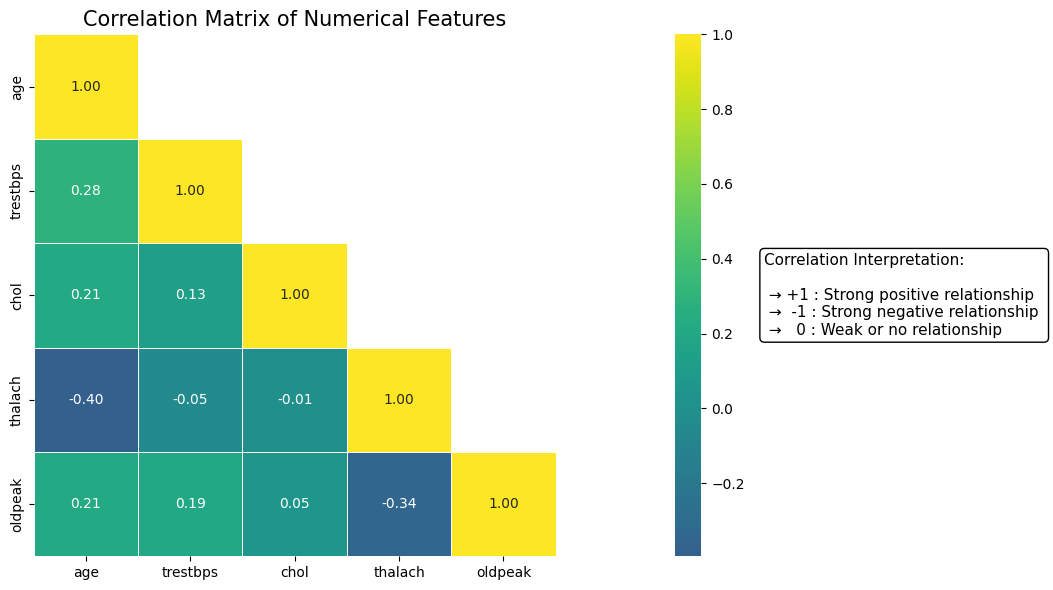

In [24]:
corr_matrix = Data[numerical_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(25, 6))

sns.heatmap(
    corr_matrix,
    mask=mask, 
    annot=True,
    fmt=".2f",
    cmap="viridis",
    center=0,
    square=True,
    linewidths=0.5
)


# Personalized legend

plt.title("Correlation Matrix of Numerical Features", fontsize=15)

legend_text = (
    "Correlation Interpretation:\n\n"
    " → +1 : Strong positive relationship \n"
    " →  -1 : Strong negative relationship \n"
    " →   0 : Weak or no relationship"
)

ax.text(
    1.40, 0.5,       
    legend_text,
    transform=ax.transAxes,
    fontsize=11,
    va="center",
    ha="left",
    bbox=dict(boxstyle="round", facecolor="white", edgecolor="black")
)

plt.tight_layout()
plt.show()

plt.show()

> ### Only the relationship between age and thalach and thalach and oldpeak can be interesting, but the relationship between the other features doesn't tell us anything special. The numerical variables appear to contain largely distinct information rather than being strongly redundant with one another.
> ##### With age, thalach tends to decrease, But -0.40 still doesn't mean a very strong relationship.
> ##### Higher values ​​of thalach tend to be associated with lower values ​​of oldpeak, which can be considered a moderate negative relationship.

## 4.2. Categorical VS Categorical features

> ### NOTE:
>> #### 1. To examine categorical features, since we have 8 features and examining pairs of these would be too much, we remove duplicate pairs.
>> #### 2. Because ordinary correlation does not directly make sense, we use Count (How many examples are in a combination of two categories?) and Percentage (What proportion of the group under study does that number constitute?) for descriptive analysis.
>> #### 3. Finally, we check whether the distribution of categories of one Feature is significantly different from other Feature categories.

In [25]:
for i in range(len(categorical_cols)):
    for j in range(i + 1, len(categorical_cols)):

        col1 = categorical_cols[i]
        col2 = categorical_cols[j]

        # Counts
        counts = pd.crosstab(
            Data[col1],
            Data[col2]
        )

        # Percentages within each category
        percentages = pd.crosstab(
            Data[col1],
            Data[col2],
            normalize="index"
        ) * 100

        # Count + Percentage
        table = pd.DataFrame(index=counts.index)

        for cat in counts.columns:
            table[f"{col2} {cat}"] = (
                "n=" + counts[cat].astype(str)
                + " /"
                + percentages[cat].round(1).astype(str)
                + "%"
            )

        table.index.name = col1

        print(f"\n{'=' * 50}")
        print(f"{col1} * {col2}")
        print(f"{'=' * 50}")
        display(table)


sex * cp


,cp 0,cp 1,cp 2,cp 3
sex,,,,
0,n=39 /40.6%,n=18 /18.8%,n=35 /36.5%,n=4 /4.2%
1,n=104 /50.5%,n=32 /15.5%,n=51 /24.8%,n=19 /9.2%



sex * fbs


,fbs 0,fbs 1
sex,,
0,n=84 /87.5%,n=12 /12.5%
1,n=173 /84.0%,n=33 /16.0%



sex * restecg


...

,ca 0,ca 1,ca 2,ca 3,ca 4
slope,,,,,
0,n=15 /71.4%,n=2 /9.5%,n=2 /9.5%,n=2 /9.5%,n=0 /0.0%
1,n=69 /49.3%,n=35 /25.0%,n=21 /15.0%,n=13 /9.3%,n=2 /1.4%
2,n=91 /64.5%,n=28 /19.9%,n=15 /10.6%,n=5 /3.5%,n=2 /1.4%



slope * thal


,thal 0,thal 1,thal 2,thal 3
slope,,,,
0,n=0 /0.0%,n=3 /14.3%,n=8 /38.1%,n=10 /47.6%
1,n=1 /0.7%,n=13 /9.3%,n=56 /40.0%,n=70 /50.0%
2,n=1 /0.7%,n=2 /1.4%,n=101 /71.6%,n=37 /26.2%



ca * thal


,thal 0,thal 1,thal 2,thal 3
ca,,,,
0,n=2 /1.1%,n=8 /4.6%,n=114 /65.1%,n=51 /29.1%
1,n=0 /0.0%,n=4 /6.2%,n=29 /44.6%,n=32 /49.2%
2,n=0 /0.0%,n=4 /10.5%,n=14 /36.8%,n=20 /52.6%
3,n=0 /0.0%,n=2 /10.0%,n=6 /30.0%,n=12 /60.0%
4,n=0 /0.0%,n=0 /0.0%,n=2 /50.0%,n=2 /50.0%


> ##### In this table, we examined different categories of different features in different pairs, and how many and what percentage of each category contains each feature.

In [26]:
summary = []

for i in range(len(categorical_cols)):
    for j in range(i + 1, len(categorical_cols)):
        
        col1 = categorical_cols[i]
        col2 = categorical_cols[j]
        
        # Normalized Crosstab
        table = pd.crosstab(
            Data[col1],
            Data[col2],
            normalize="index"
        ) * 100
        
        # Maximum difference between groups for each category of col2
        max_diff = (table.max(axis=0) - table.min(axis=0))
        
        # Find the category with the largest difference
        largest_diff = max_diff.max()
        category = max_diff.idxmax()
        
        # Store result
        summary.append({
            "Pair": f"{col1} * {col2}",
            "Max Difference (%)": largest_diff,
            "Category": f"{col2} = {category}"
        })

# Convert to DataFrame
summary_df = pd.DataFrame(summary)

# Sort from highest to lowest difference
summary_df = summary_df.sort_values(
    "Max Difference (%)",
    ascending=False
).reset_index(drop=True)

# Round percentage
summary_df["Max Difference (%)"] = summary_df["Max Difference (%)"].round(2)

summary_df

,Pair,Max Difference (%),Category
0,restecg * slope,54.30,slope = 2
1,cp * exang,47.94,exang = 1
2,cp * thal,41.64,thal = 2
3,sex * thal,40.54,thal = 2
4,cp * slope,38.43,slope = 2
5,ca * thal,35.14,thal = 2
6,exang * thal,34.70,thal = 2
7,slope * thal,33.54,thal = 2
8,exang * slope,30.39,slope = 2
9,cp * ca,28.55,ca = 0


> ##### After calculating the Count for each pair and the Percentage within each group, we calculate the difference between the highest and lowest percentages in the different groups. Then we determine which Category has the largest difference.
> ##### In fact, the goal is to find in which pair the distribution of categories shows the greatest difference between the groups.

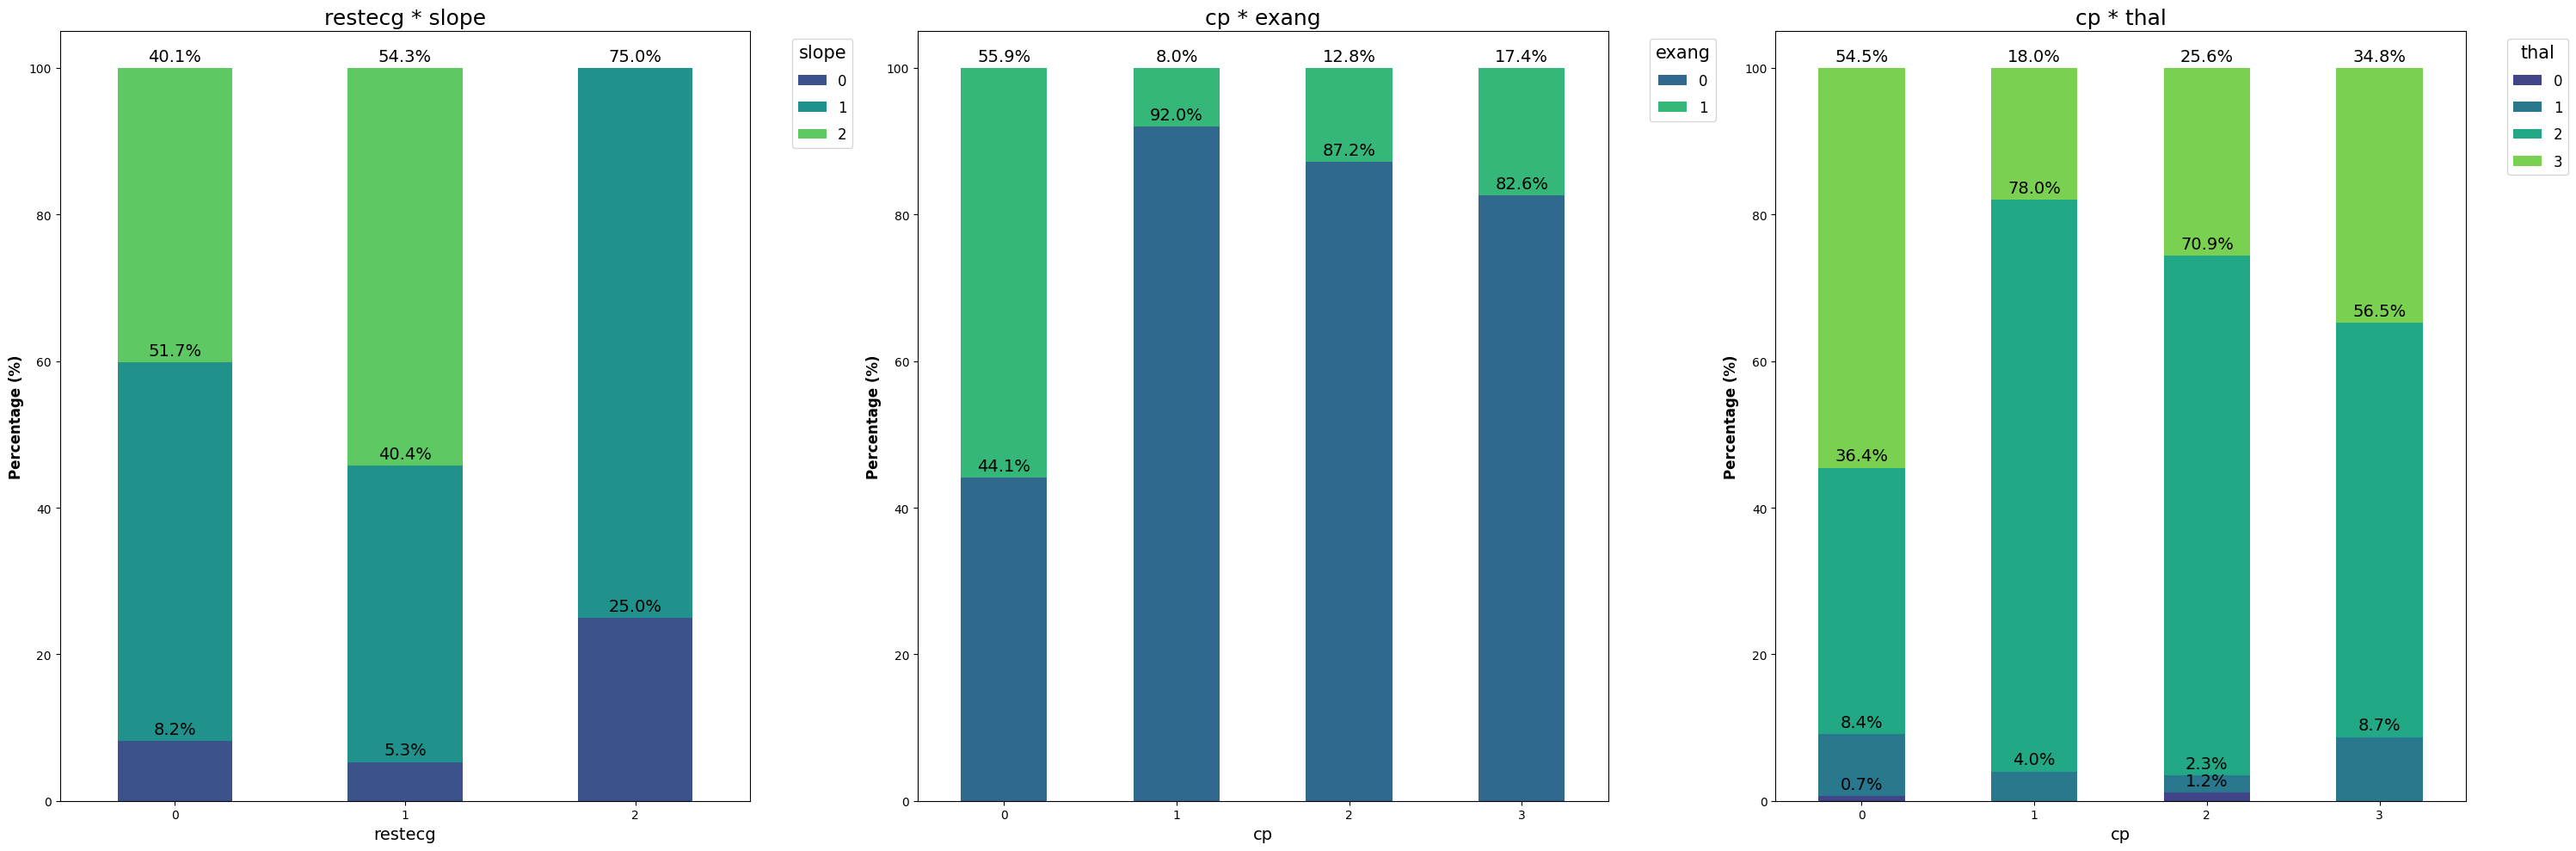

In [27]:
pairs = [
    ("restecg", "slope"),
    ("cp", "exang"),
    ("cp", "thal")
]

fig, axes = plt.subplots(1, 3, figsize=(30, 10))

for ax, (col1, col2) in zip(axes, pairs):
    percentages = pd.crosstab(
        Data[col1],
        Data[col2],
        normalize="index"
    ) * 100

    n_categories = Data[col2].nunique()
    palette = sns.color_palette("viridis", n_colors=n_categories)

    percentages.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        color=palette
    )

    ax.set_title(
        f"{col1} * {col2}",
        fontsize=18
        )

    ax.set_xlabel(
        col1,
        fontsize=14
        )
    
    ax.set_ylabel(
        "Percentage (%)",
        fontweight="bold",
        fontsize=12
        )

    ax.legend(
        title=col2,
        bbox_to_anchor=(1.05, 1),
        title_fontsize=15, 
        fontsize=12,
        labelspacing=0.8,
        loc="upper left"
    )
    ax.tick_params(axis="x", rotation=0)

    for container in ax.containers:
        labels = [f"{v:.1f}%" if v > 0 else "" for v in container.datavalues]
        ax.bar_label(
         container,
             labels=labels,
             label_type="edge",
             padding=3,
             fontsize=14,
             color="black"
        )

plt.tight_layout()
plt.show()

> ### restecg * slope : 
>> #### As we saw in our pair description table, this pair has a total of 4 samples in the restecg=2 column (slope=2 has none at all), so we ignore it altogether.
>> #### But in the restecg=0.1 column, it can be seen that slope=2 has a good increase.
> ### cp * exang :
>> #### cp=0 is the only category where exang=1 is not dominant but is relatively high (55.9%), while cp=1,2,3 are all between 8% and 17.4%. This means that the type of chest pain of cp=0 is strongly associated with the presence of exercise-induced angina (exang=1). Means, The distribution of exang changes drastically with the change in cp.
> ### cp * thal :
>> #### As cp changes, the distribution of thal changes significantly. These pairs are also interrelated.

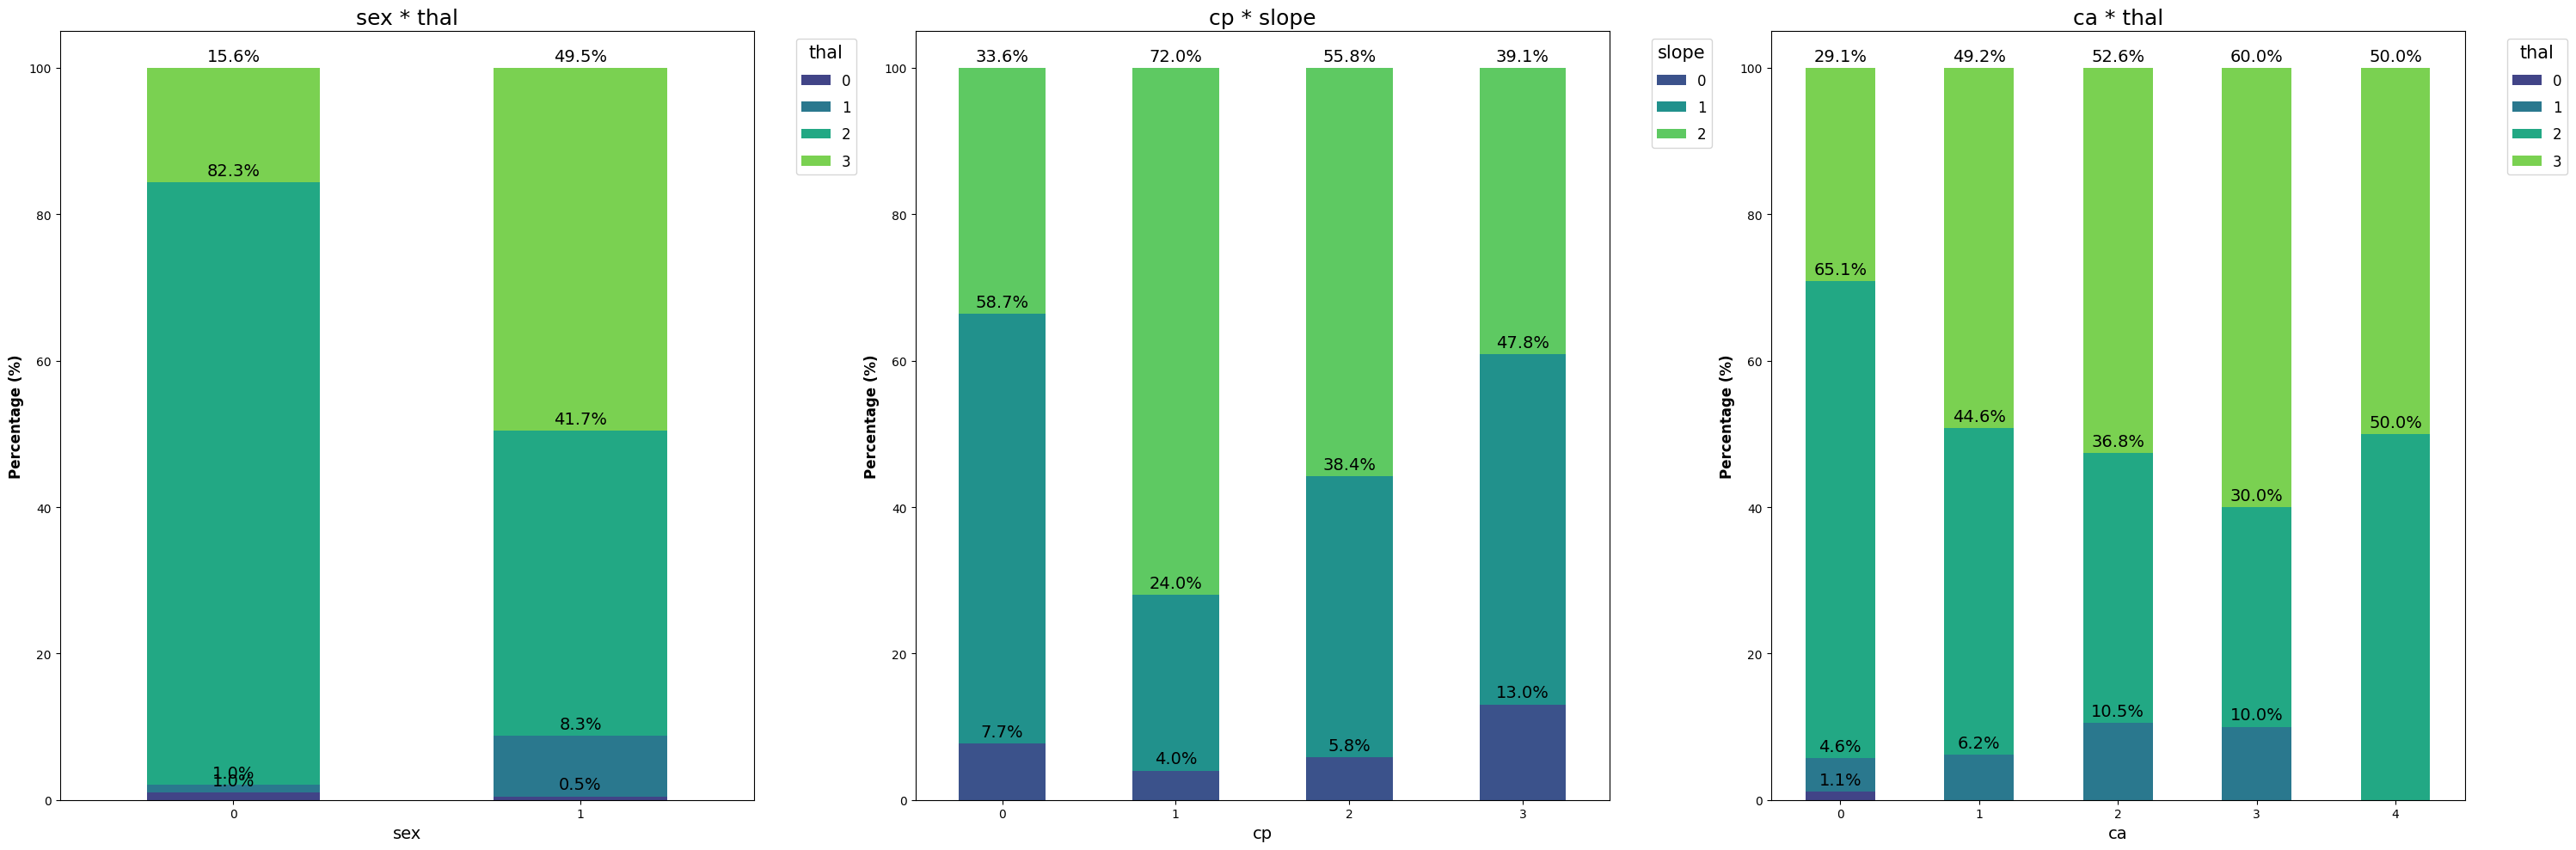

In [28]:
pairs = [
    ("sex", "thal"),
    ("cp", "slope"),
    ("ca", "thal")
]

fig, axes = plt.subplots(1, 3, figsize=(30, 10))

for ax, (col1, col2) in zip(axes, pairs):
    percentages = pd.crosstab(
        Data[col1],
        Data[col2],
        normalize="index"
    ) * 100

    n_categories = Data[col2].nunique()
    palette = sns.color_palette("viridis", n_colors=n_categories)

    percentages.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        color=palette
    )

    ax.set_title(
        f"{col1} * {col2}",
        fontsize=18
    )

    ax.set_xlabel(
        col1,
        fontsize=14
        )
    
    ax.set_ylabel(
        "Percentage (%)",
        fontweight="bold",
        fontsize=12
    )

    ax.legend(
        title=col2,
        bbox_to_anchor=(1.05, 1),
        title_fontsize=15,
        fontsize=12,
        labelspacing=0.8,
        loc="upper left"
    )

    ax.tick_params(axis="x", rotation=0)

    for container in ax.containers:
        labels = [
            f"{v:.1f}%" if v > 0 else ""
            for v in container.datavalues
        ]

        ax.bar_label(
            container,
            labels=labels,
            label_type="edge",
            padding=3,
            fontsize=14,
            color="black"
        )

plt.tight_layout()
plt.show()

> ### sex * thal : 
>> #### Women (sex=0) predominantly have thal=2 (82.3%) and rarely have thal=3 (15.6%), but men (sex=1) are more widespread and have thal=3 almost as much as thal=2 (49.5% vs. 41.7%).
> ### cp * slope :
>> #### The slope distribution is not the same across the different cp classes. his is consistent with the cp×thal and cp×exang patterns: cp=0 consistently falls into different patterns than the rest of the cp classes.
> ### ca * thal :
>> #### As we saw in our pair description table, this pair has a total of 5 samples in the ca=4 column, so we ignore it altogether.
>> #### As (ca) increases, the proportion of thal=3 increases almost uniformly. That is, the higher the number of (ca), the higher the probability of thal=3.

## 4.3. Categorical VS Numerical features

> ##### Because it is very time-consuming and difficult to examine all the features, to see how much the numerical features differ between the categorical feature groups, we compare the Median of each group, which is more robust to outliers than the Mean.

In [29]:
summary = []

for num_col in numerical_cols:
    for cat_col in categorical_cols:

        group_medians = Data.groupby(cat_col)[num_col].median()

        median_diff = (
            group_medians.max()
            - group_medians.min()
        )

        summary.append({
            "Pair": f"{num_col} × {cat_col}",
            "Median Difference": round(median_diff, 2)
        })

summary_df = pd.DataFrame(summary)

summary_df = summary_df.sort_values(
    "Median Difference",
    ascending=False
).reset_index(drop=True)

display(summary_df)

,Pair,Median Difference
0,chol × ca,48.50
1,thalach × restecg,34.50
2,chol × thal,33.00
3,chol × restecg,28.50
4,thalach × thal,24.50
5,thalach × ca,22.50
6,thalach × cp,20.50
7,thalach × exang,20.00
8,thalach × slope,20.00
9,chol × sex,18.00


> ##### We have listed the Median difference of each group in order from top to bottom. Now let's look at the first 6.

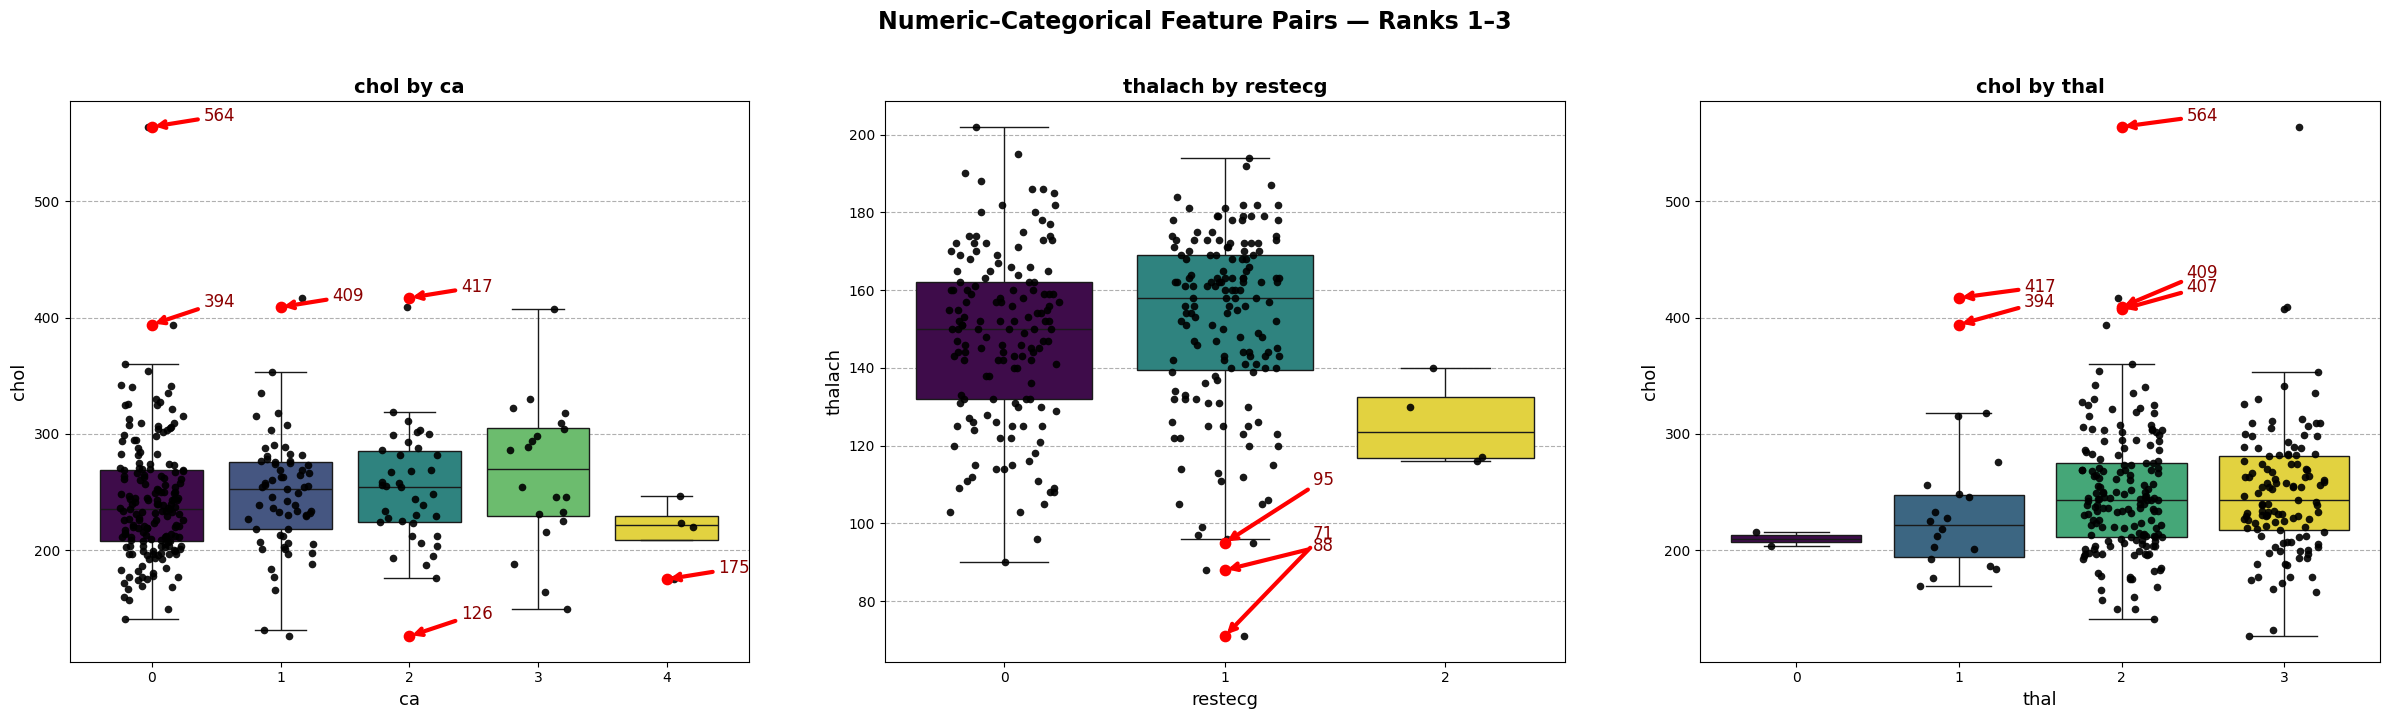

In [ ]:
pairs = [
    ("chol", "ca"),
    ("thalach", "restecg"),
    ("chol", "thal")
]

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for ax, (num_col, cat_col) in zip(axes, pairs):

    # Boxplot
    sns.boxplot(
        data=Data,
        x=cat_col,
        y=num_col,
        hue=cat_col,
        legend=False,
        ax=ax,
        palette="viridis",
        showmeans=False,
        showfliers=False,
    )

    # Displaying all data points
    sns.stripplot(
        data=Data,
        x=cat_col,
        y=num_col,
        ax=ax,
        color="black",
        size=5.5,
        alpha=0.9,
        jitter=0.25
    )

    # Detecting and plotting outliers
    for i, category in enumerate(Data[cat_col].dropna().unique()):

        values = Data.loc[
            Data[cat_col] == category, num_col
        ].dropna()

        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        outliers = values[
            (values < lower) | (values > upper)
        ]

        ax.scatter(
            [i] * len(outliers),
            outliers,
            color="red",
            s=55,
            zorder=10
        )

        # Marking outliers with their values
        
        label_fontsize = 12
        dx = 0.40
        dy_base = 5 
        dy_step = 10 

        for k, y_val in enumerate(outliers):
            ax.annotate(
             f"{y_val:.0f}",
             xy=(i, y_val),
             xytext=(i + dx, y_val + dy_base + k * dy_step),
             fontsize=label_fontsize,
             color="darkred",
             arrowprops=dict(
             arrowstyle="->",
             color="red",
             lw=3
            )
       )

    ax.set_title(
        f"{num_col} by {cat_col}",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel(cat_col, fontsize=13)
    ax.set_ylabel(num_col, fontsize=13)

    ax.grid(axis="y", linestyle="--", alpha=1)

plt.suptitle(
    "Numeric–Categorical Feature Pairs — Ranks 1–3",
    fontsize=17,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.subplots_adjust(wspace=0.2)
plt.show()

> ### chol * ca :
>> #### The data distribution pattern, scatter, overlap, and median of all CA groups are almost the same.
>> #### In almost every ca groups, outliers are found that are very far from the distribution of data in that groups.
>> #### Here  it is better to ignore ca=4.
> ### thalach * restecg :
>> #### At restecg=0/1 the data overlap and median are almost the same.
>> #### At restecg=1 only outlier data is visible.
>> #### Here too it is better to ignore restecg=2.
> ### thal * chol :
>> #### Almost all groups are close together.
>> #### There is a strong overlap in the thal=2/3 group.
>> #### There are very extreme outliers with unreasonable distances in thal=1/2.
>> #### Here too we can ignore thal=0.

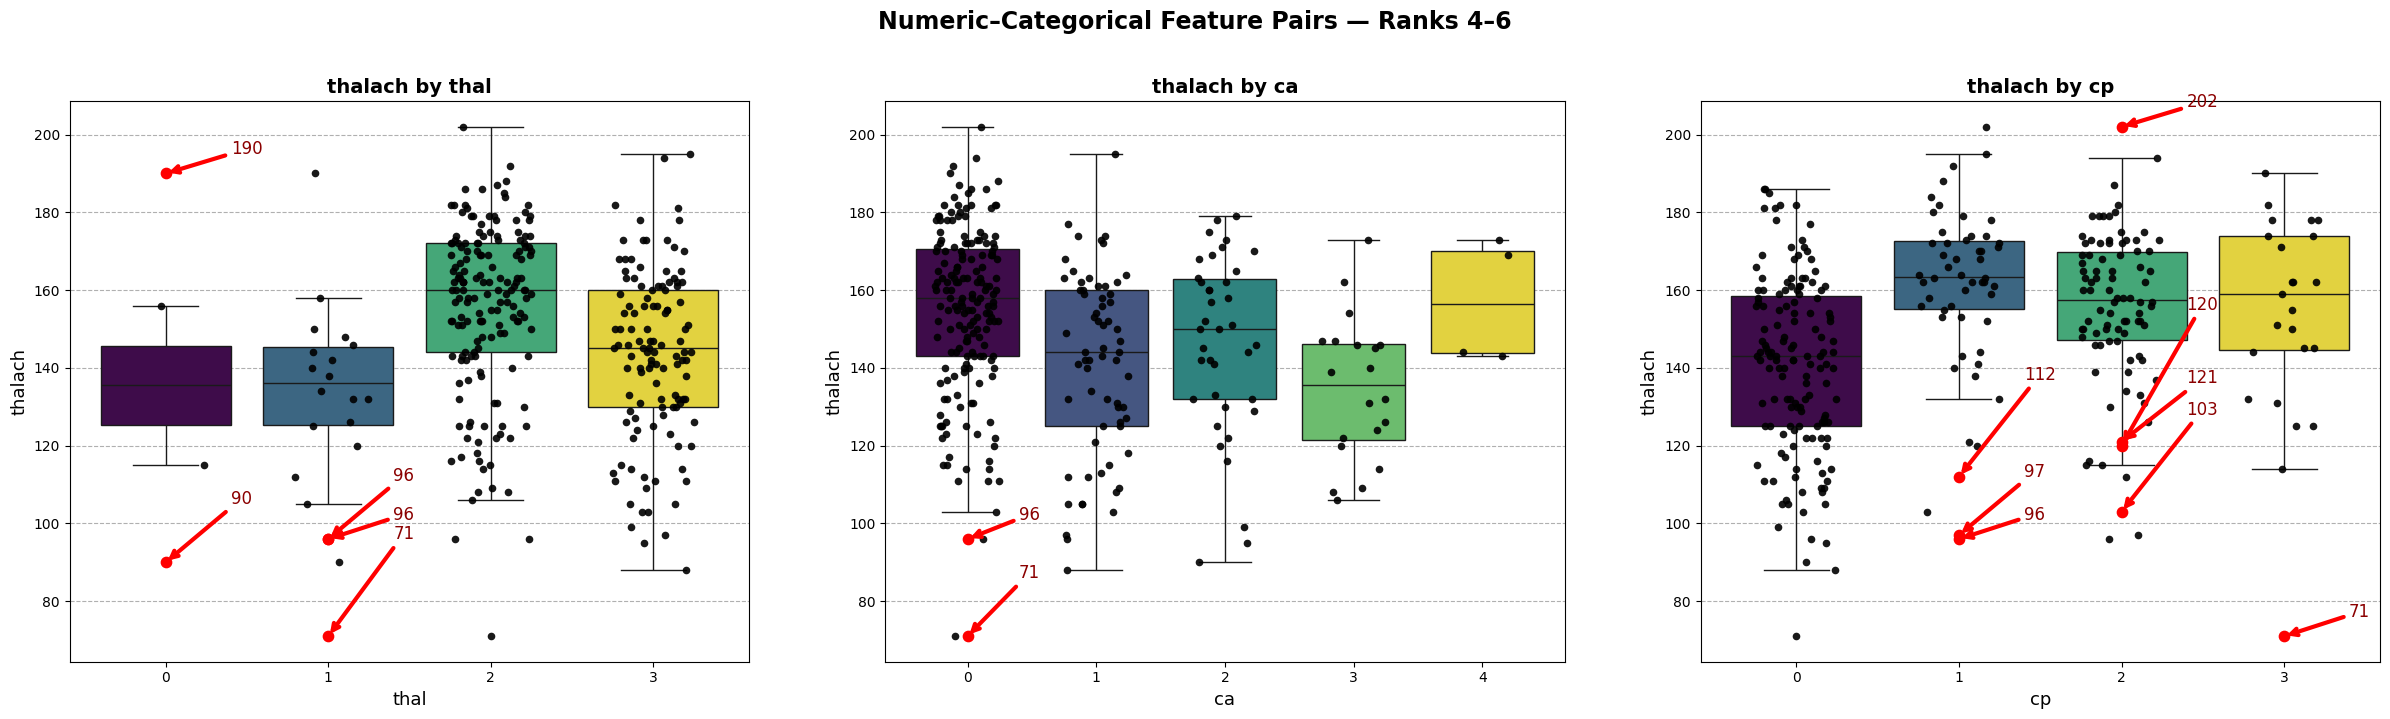

In [31]:
pairs = [
    ("thalach", "thal"),
    ("thalach", "ca"),
    ("thalach", "cp")
]

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for ax, (num_col, cat_col) in zip(axes, pairs):

    # Boxplot
    sns.boxplot(
        data=Data,
        x=cat_col,
        y=num_col,
        hue=cat_col,
        legend=False,
        ax=ax,
        palette="viridis",
        showmeans=False,
        showfliers=False,
    )

    # Displaying all data points
    sns.stripplot(
        data=Data,
        x=cat_col,
        y=num_col,
        ax=ax,
        color="black",
        size=5.5,
        alpha=0.9,
        jitter=0.25
    )

    # Detecting and plotting outliers
    for i, category in enumerate(Data[cat_col].dropna().unique()):

        values = Data.loc[
            Data[cat_col] == category, num_col
        ].dropna()

        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        outliers = values[
            (values < lower) | (values > upper)
        ]

        ax.scatter(
            [i] * len(outliers),
            outliers,
            color="red",
            s=55,
            zorder=10
        )

        # Marking outliers with their values
        
        label_fontsize = 12
        dx = 0.40
        dy_base = 5 
        dy_step = 10 

        for k, y_val in enumerate(outliers):
            ax.annotate(
             f"{y_val:.0f}",
             xy=(i, y_val),
             xytext=(i + dx, y_val + dy_base + k * dy_step),
             fontsize=label_fontsize,
             color="darkred",
             arrowprops=dict(
             arrowstyle="->",
             color="red",
             lw=3
            )
       )

    ax.set_title(
        f"{num_col} by {cat_col}",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel(cat_col, fontsize=13)
    ax.set_ylabel(num_col, fontsize=13)

    ax.grid(axis="y", linestyle="--", alpha=1)

plt.suptitle(
    "Numeric–Categorical Feature Pairs — Ranks 4–6",
    fontsize=17,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.subplots_adjust(wspace=0.2)
plt.show()

> ### thalach * thal :
>> #### At thal=0.1 they are almost equal in the middle, thal=3 is close to them but thal=2 is far from them.
>> #### AOverlap is seen at thal=2.3 and thal=0.1.
>> #### AScattered data, some of which are very extreme and spaced.
> ### thalach * ca :
>> #### High overlap between all groups.
>> #### Outliers are mainly seen at ca=0 at low values.
> ### thalach * cp :
>> #### Medium overlap; cp=1/2/3 have a lot of overlap.
>> #### Scattered outliers exist in all clusters.


# ✅ 5. Conclusion

> ### Overall, the dataset appears to have a relatively balanced target distribution, with no major problems with outliers.
> ### The numerical variables generally exhibit weak pairwise correlations, indicating limited redundancy among them.
> ### The most notable features from the EDA are: thalach, oldpeak, age, chol, ca, and thal
> ### The EDA also reveals that some categorical variables, particularly cp, thal, ca, slope, restecg, and exang, exhibit substantial distributional differences when compared with other categorical or numerical variables.
> ### We identified several feature interactions—particularly involving thalach, oldpeak, chol, ca, thalamus, and cp—that warrant further investigation in the next step.